# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours

---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [ ]:
%pip install pandas

import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [ ]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation

The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### Tasks
1. Report dataset dimensions, class balance, missing values, duplicates and summary statistics.
2. Identify the identifier and the post-scan field. Explain why each should be excluded.
3. Investigate `Virtual_to_Raw_Size_Ratio`: identify the suspicious parser value `99999.0`. Decide how to handle it and justify your choice.
4. Visualize at least two feature relationships with the target. Discuss whether a single linear boundary is likely to capture all patterns.
5. Define the prediction task, positive class, and the operational meaning of FP and FN.

**Do not** use `VT_PostScan_Detections` as an input feature. It is recorded after the event and would cause target leakage.

In [ ]:
print("Shape:", df_pe.shape)
print("\nClass balance (counts):\n", df_pe["Is_Malware"].value_counts())
print("\nClass balance (%):\n", df_pe["Is_Malware"].value_counts(normalize=True).round(3))
print("\nMissing values:\n", df_pe.isna().sum())
print("\nDuplicate rows:", df_pe.duplicated().sum())
print("Duplicate file IDs:", df_pe["SHA256_File_ID"].duplicated().sum())

# Leakage check: how strongly does the post-scan field track the label?
print("\nMean VT_PostScan_Detections by class:")
print(df_pe.groupby("Is_Malware")["VT_PostScan_Detections"].describe())

display(df_pe.describe().T)

Shape: (6000, 15)

Class balance (counts):
 Is_Malware
0    4389
1    1611
Name: count, dtype: int64

Class balance (%):
 Is_Malware
0    0.732
1    0.268
Name: proportion, dtype: float64

Missing values:
 SHA256_File_ID                  0
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio       0
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
VT_PostScan_Detections          0
Is_Malware                      0
dtype: int64

Duplicate rows: 0
Duplicate file IDs: 0

Mean VT_PostScan_Detections by class:
             count       mean        std   min   25%   50%   75%   max
Is_Malware                                                            
0           4389.0   0.989747   0.821672   0.0   

,count,mean,std,min,25%,50%,75%,max
Max_Section_Entropy,6000.0,5.709010,1.170152,2.146111,4.821742,5.639862,6.604762,7.990000
Import_Count,5771.0,83.386866,50.301130,0.000000,41.184528,85.663796,120.408591,320.325585
Suspicious_API_Imports,6000.0,2.800167,3.094430,0.000000,1.000000,2.000000,3.000000,24.000000
Has_Valid_Signature,6000.0,0.630833,0.482619,0.000000,0.000000,1.000000,1.000000,1.000000
Has_RWX_Section,6000.0,0.149833,0.356938,0.000000,0.000000,0.000000,0.000000,1.000000
Virtual_to_Raw_Size_Ratio,6000.0,984.890348,9868.008483,0.367195,0.955570,1.129836,1.366755,99999.000000
Resource_Entropy,5711.0,4.535160,1.501097,0.000000,3.483114,4.432941,5.517712,7.990000
Num_Embedded_URLs_IPs,6000.0,1.468333,1.951742,0.000000,0.000000,1.000000,2.000000,11.000000
Abnormal_Compile_Timestamp,6000.0,0.114833,0.318847,0.000000,0.000000,0.000000,0.000000,1.000000
Num_Sections,6000.0,4.758667,1.784551,1.000000,3.000000,5.000000,6.000000,10.000000


Rows with Virtual_to_Raw_Size_Ratio == 99999.0: 59 (0.98%)

Ratio stats excluding 99999.0:
count    5941.000000
mean        1.582408
std         1.298046
min         0.367195
25%         0.953186
50%         1.126470
75%         1.355024
max         6.497630
Name: Virtual_to_Raw_Size_Ratio, dtype: float64


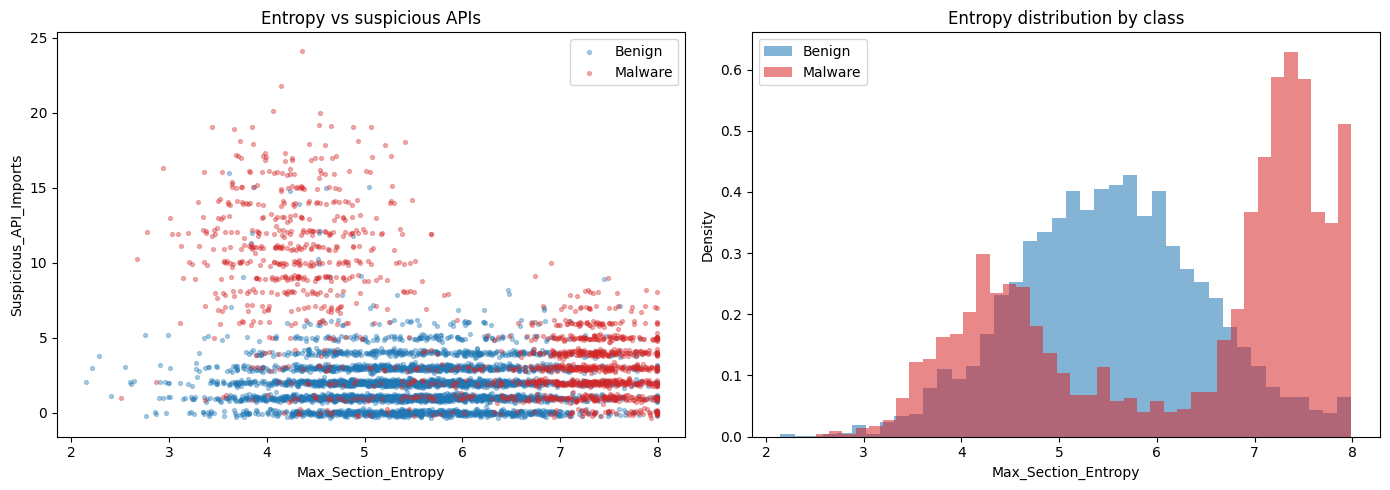

In [ ]:
ratio = df_pe["Virtual_to_Raw_Size_Ratio"]
n_bad = (ratio == 99999.0).sum()
print(f"Rows with Virtual_to_Raw_Size_Ratio == 99999.0: {n_bad} ({n_bad/len(df_pe):.2%})")
print("\nRatio stats excluding 99999.0:")
print(ratio[ratio != 99999.0].describe())

rng_plot = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: entropy vs suspicious APIs (jitter on the discrete count axis)
for label, name, color in [(0, "Benign", "tab:blue"), (1, "Malware", "tab:red")]:
    sub = df_pe[df_pe["Is_Malware"] == label]
    jitter = rng_plot.normal(0, 0.12, len(sub))
    axes[0].scatter(sub["Max_Section_Entropy"], sub["Suspicious_API_Imports"] + jitter,
                    s=8, alpha=0.35, label=name, color=color)
axes[0].set_xlabel("Max_Section_Entropy")
axes[0].set_ylabel("Suspicious_API_Imports")
axes[0].set_title("Entropy vs suspicious APIs")
axes[0].legend()

# Plot 2: entropy distribution by class (shows non-linear / multi-modal pattern)
for label, name, color in [(0, "Benign", "tab:blue"), (1, "Malware", "tab:red")]:
    axes[1].hist(df_pe.loc[df_pe["Is_Malware"] == label, "Max_Section_Entropy"],
                 bins=40, alpha=0.55, label=name, color=color, density=True)
axes[1].set_xlabel("Max_Section_Entropy")
axes[1].set_ylabel("Density")
axes[1].set_title("Entropy distribution by class")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
TARGET = "Is_Malware"
y = df_pe[TARGET].astype(int)

X = df_pe.drop(columns=["SHA256_File_ID", "VT_PostScan_Detections", TARGET]).copy()
X["Virtual_to_Raw_Size_Ratio"] = X["Virtual_to_Raw_Size_Ratio"].replace(99999.0, np.nan)

print("X shape:", X.shape)
print("Remaining NaNs per column:\n", X.isna().sum())

X shape: (6000, 12)
Remaining NaNs per column:
 Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio      59
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
dtype: int64


## Phase 2 — Design a leakage-safe evaluation protocol

Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### Tasks
1. Create `X_dev`, `X_test`, `y_dev`, `y_test`.
2. Define a preprocessing pipeline with median imputation. Use `RobustScaler` for Logistic Regression; explain why scaling is generally unnecessary for tree models.
3. Build candidate pipelines:
   - Logistic Regression (linear baseline)
   - Deep Decision Tree (single white-box tree)
   - Random Forest (bagging)
   - LightGBM if installed; otherwise `HistGradientBoostingClassifier` and label it accurately (not LightGBM).
4. Use the same CV folds and report train F1, validation F1, PR-AUC and fit time.
5. Interpret bias/variance and choose candidates worth further investigation.

In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print("Dev:", X_dev.shape, "| Test (lockbox):", X_test.shape)
print("Dev prevalence:", round(y_dev.mean(), 3), "| Test prevalence:", round(y_test.mean(), 3))

def make_pipe(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", RobustScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

# Boosting: LightGBM if installed, otherwise sklearn's HistGradientBoosting (labelled accurately)
try:
    from lightgbm import LGBMClassifier
    boost = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                           random_state=SEED, verbose=-1, n_jobs=1)
    BOOST_NAME = "LightGBM"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    boost = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED)
    BOOST_NAME = "HistGradientBoosting (sklearn)"
print("Boosting model used:", BOOST_NAME)

lr_model = LogisticRegression(max_iter=2000, random_state=SEED)
dt_model = DecisionTreeClassifier(max_depth=None, random_state=SEED)   # deliberately deep
rf_model = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)

# Heterogeneous stacking (imputer outside, so base learners get clean data)
stack_model = StackingClassifier(
    estimators=[
        ("lr", Pipeline([("scaler", RobustScaler()),
                         ("m", LogisticRegression(max_iter=2000, random_state=SEED))])),
        ("rf", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)),
        ("boost", clone(boost)),
    ],
    final_estimator=LogisticRegression(max_iter=2000, random_state=SEED),
    stack_method="predict_proba",
    cv=5,
    n_jobs=1,
)

candidates = {
    "Logistic Regression": make_pipe(lr_model, scale=True),
    "Decision Tree (deep)": make_pipe(dt_model),
    "Random Forest": make_pipe(rf_model),
    BOOST_NAME: make_pipe(boost),
    "Stacking": make_pipe(stack_model),
}

Dev: (4800, 12) | Test (lockbox): (1200, 12)
Dev prevalence: 0.269 | Test prevalence: 0.268
Boosting model used: LightGBM


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"f1": "f1", "ap": "average_precision"}

rows = []
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_dev, y_dev, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    rows.append({
        "Model": name,
        "Train F1": res["train_f1"].mean(),
        "Val F1": res["test_f1"].mean(),
        "Val F1 std": res["test_f1"].std(),
        "Val PR-AUC": res["test_ap"].mean(),
        "Fit time (s/fold)": res["fit_time"].mean(),
    })

cv_table = pd.DataFrame(rows).set_index("Model")
cv_table["Train-Val gap"] = cv_table["Train F1"] - cv_table["Val F1"]
display(cv_table.round(4).sort_values("Val PR-AUC", ascending=False))

,Train F1,Val F1,Val F1 std,Val PR-AUC,Fit time (s/fold),Train-Val gap
Model,,,,,,
Stacking,0.9572,0.9244,0.0088,0.9084,17.8918,0.0328
Logistic Regression,0.9231,0.9238,0.0084,0.9080,0.0337,-0.0007
Random Forest,1.0000,0.9237,0.0091,0.9054,4.4146,0.0763
LightGBM,0.9979,0.9217,0.0091,0.9033,1.2387,0.0762
Decision Tree (deep),1.0000,0.8301,0.0135,0.7330,0.0737,0.1699


### Decision checkpoint 1 — Select a shortlist

Answer with evidence from your table:
1. Which model shows the largest train–validation gap? What does it suggest?
2. Does the linear baseline already perform competitively?
3. Does Random Forest improve on the single tree?
4. Does boosting improve PR-AUC enough to justify its complexity?
5. Is stacking justified by the measured gain, runtime and deployment context? Do not assume that a more complex model must win.

**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements.

In [ ]:
# Fit on dev only (reused later in the error-forensics and threshold cells)
fitted = {name: clone(pipe).fit(X_dev, y_dev) for name, pipe in candidates.items()}

batch = X_test.iloc[:1000]          # features only, no labels used
lat_rows = []
for name, model in fitted.items():
    model.predict_proba(batch)      # warm-up
    times = []
    for _ in range(10):
        t0 = time.perf_counter()
        model.predict_proba(batch)
        times.append((time.perf_counter() - t0) * 1000)
    lat_rows.append({"Model": name,
                     "ms / 1,000 files (median)": np.median(times),
                     "ms / 1,000 files (min)": np.min(times)})

display(pd.DataFrame(lat_rows).set_index("Model").round(2))
print("Note: single machine/runtime, batch inference, 10 repeats; not a production benchmark.")

,"ms / 1,000 files (median)","ms / 1,000 files (min)"
Model,,
Logistic Regression,2.64,2.55
Decision Tree (deep),2.50,2.43
Random Forest,60.06,57.87
LightGBM,30.65,29.76
Stacking,69.57,68.84


Note: single machine/runtime, batch inference, 10 repeats; not a production benchmark.


## Phase 3 — Error forensics: investigate a real disagreement

Choose a held-out test observation for which the candidate models disagree. Do not hard-code a story before verifying the predictions.

### Tasks
1. Generate probabilities for the same test observations from Logistic Regression and your selected tree ensemble.
2. Find a malware observation where Logistic Regression predicts benign at the chosen illustrative threshold while the tree model predicts malware. If no such observation exists, report that honestly and choose another meaningful disagreement.
3. Print the ground-truth label, feature values, probabilities and predictions.
4. Build global and local SHAP explanations for a supported tree model.
5. Interpret a beeswarm and a local waterfall. Explain why SHAP is not causal evidence.

In [ ]:
TREE_NAME = "Random Forest"
THR_DIAG = 0.50   # diagnostic only

p_lr = fitted["Logistic Regression"].predict_proba(X_test)[:, 1]
p_tree = fitted[TREE_NAME].predict_proba(X_test)[:, 1]
pred_lr = (p_lr >= THR_DIAG).astype(int)
pred_tree = (p_tree >= THR_DIAG).astype(int)
y_true = y_test.values

# Malware that LR calls benign but the tree model calls malware
mask = (y_true == 1) & (pred_lr == 0) & (pred_tree == 1)
print("Malware caught by tree but missed by LR:", mask.sum())

if mask.sum() > 0:
    idx = np.where(mask)[0]
    i = idx[np.argmax(p_tree[idx] - p_lr[idx])]    # largest probability gap
else:
    print("No such case; falling back to any LR/tree disagreement.")
    idx = np.where(pred_lr != pred_tree)[0]
    i = idx[0]

print("\nTest row position:", i)
print("y_true:", y_true[i], "| LR prob:", round(p_lr[i], 3), "pred:", pred_lr[i],
      "| Tree prob:", round(p_tree[i], 3), "pred:", pred_tree[i])
display(X_test.iloc[[i]].T)

Malware caught by tree but missed by LR: 2

Test row position: 548
y_true: 1 | LR prob: 0.426 pred: 0 | Tree prob: 0.967 pred: 1


,5115
Max_Section_Entropy,7.221465
Import_Count,13.184508
Suspicious_API_Imports,1.000000
Has_Valid_Signature,0.000000
Has_RWX_Section,0.000000
Virtual_to_Raw_Size_Ratio,2.330997
Resource_Entropy,5.381376
Num_Embedded_URLs_IPs,1.000000
Abnormal_Compile_Timestamp,0.000000
Num_Sections,10.000000


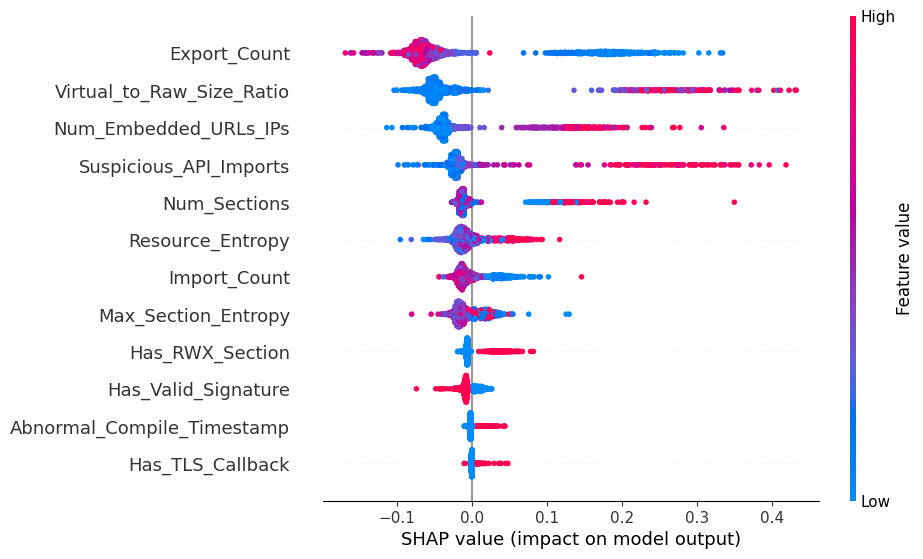

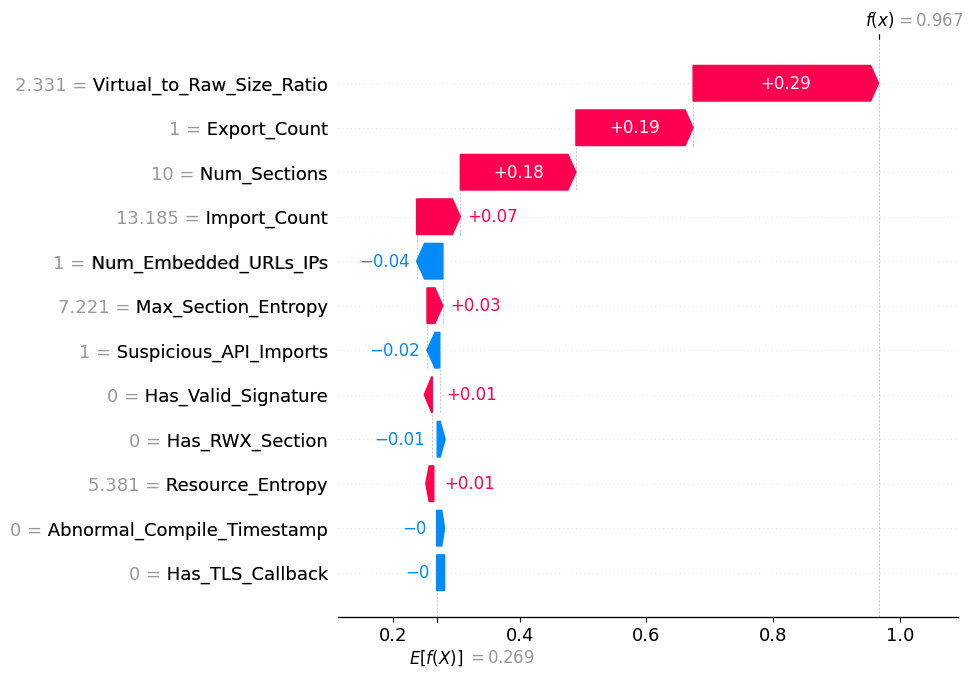

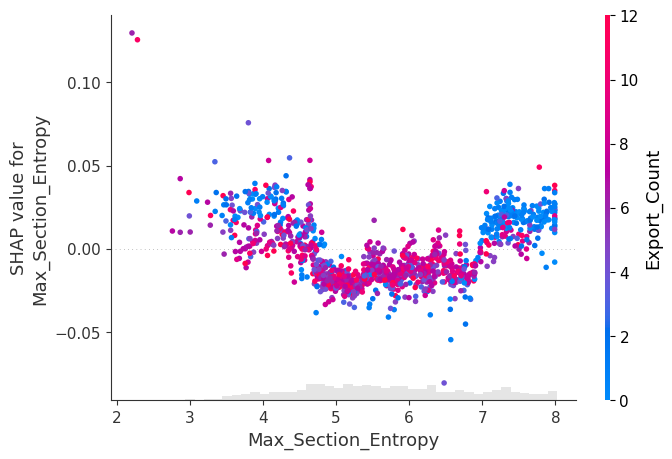

In [ ]:
# !pip install shap     # uncomment if needed
import shap

pipe_tree = fitted[TREE_NAME]
imputer = pipe_tree.named_steps["imputer"]
tree_clf = pipe_tree.named_steps["model"]

X_test_imp = pd.DataFrame(imputer.transform(X_test),
                          columns=X_test.columns, index=X_test.index)

explainer = shap.TreeExplainer(tree_clf)
sv = explainer(X_test_imp)
if sv.values.ndim == 3:        # (n, features, classes) -> keep malware class
    sv = sv[:, :, 1]

# Global: beeswarm
shap.plots.beeswarm(sv, max_display=13)

# Local: waterfall for the verified case from the previous cell
shap.plots.waterfall(sv[i], max_display=13)

# Optional: dependence plot
shap.plots.scatter(sv[:, "Max_Section_Entropy"], color=sv)

## Phase 4 — Translate model scores into a SOC decision

For the AtlasPay teaching scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.

\[
C(\tau)=25\,FP(\tau)+500\,FN(\tau)
\]

### Critical protocol
Select the threshold using development data only (for example, out-of-fold development predictions). Freeze the selected threshold. Evaluate it once on the lockbox test set. Never search test thresholds and report the minimum as final performance.

### Tasks
1. Generate out-of-fold probabilities for each shortlisted model on the development set.
2. Find the cost-minimizing threshold on those OOF predictions.
3. Freeze the threshold and evaluate FP, FN, precision, recall and cost on the test set.
4. Repeat threshold selection under `C_FP = $2,000` using development predictions. Explain why the preferred threshold changes.
5. Discuss the limitations of the cost assumptions and whether the dataset prevalence represents the intended deployment environment.

**Capacity check:** Compare the number of test-set alerts at your frozen threshold with the scenario’s 120-alert/day target only as an indicative exercise. The test set is a sample, the dataset prevalence is synthetic, and a simple test-set count must not be presented as a validated daily alert forecast. Explain what real telemetry and calibration would be required.

In [ ]:
COST_FP, COST_FN = 25, 500
COST_FP_BLOCK = 2000
grid = np.round(np.linspace(0.01, 0.99, 99), 2)

def cost_curve(y_true, p, c_fp, c_fn):
    out = []
    for t in grid:
        pred = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        out.append((t, fp, fn, c_fp * fp + c_fn * fn))
    return pd.DataFrame(out, columns=["thr", "FP", "FN", "cost"])

shortlist = ["Logistic Regression", "Random Forest", BOOST_NAME]

# 1) OOF probabilities on the development set only
oof = {n: cross_val_predict(candidates[n], X_dev, y_dev, cv=cv,
                            method="predict_proba", n_jobs=-1)[:, 1]
       for n in shortlist}

# 2) Optimise thresholds on OOF only, for both cost scenarios
best_thr = {}
for n in shortlist:
    for tag, c_fp in [("triage", COST_FP), ("blocking", COST_FP_BLOCK)]:
        cc = cost_curve(y_dev.values, oof[n], c_fp, COST_FN)
        best_thr[(n, tag)] = cc.loc[cc["cost"].idxmin(), "thr"]

# 3) Freeze thresholds, evaluate ONCE on the lockbox test set
rows = []
for n in shortlist:
    p_test = fitted[n].predict_proba(X_test)[:, 1]
    for tag, c_fp in [("triage", COST_FP), ("blocking", COST_FP_BLOCK)]:
        t = best_thr[(n, tag)]
        pred = (p_test >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
        rows.append({
            "Model": n, "Scenario": tag, "Frozen thr": t,
            "FP": fp, "FN": fn, "TP": tp,
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "Test cost ($)": c_fp * fp + COST_FN * fn,
            "Alerts in test": tp + fp,
            "Indicative alerts/day*": (tp + fp) / len(y_test) * 12000,
        })

results = pd.DataFrame(rows).set_index(["Model", "Scenario"])
display(results.round(3))
print("*Indicative only: scales the test-sample alert rate to 12,000 files/day under synthetic prevalence; not a validated forecast.")

Frozen thr  FP  FN   TP  Precision  Recall  \
Model               Scenario                                               
Logistic Regression triage          0.28  10  34  288      0.966   0.894   
                    blocking        0.50   8  36  286      0.973   0.888   
Random Forest       triage          0.33  12  34  288      0.960   0.894   
                    blocking        0.70   8  40  282      0.972   0.876   
LightGBM            triage          0.12  26  34  288      0.917   0.894   
                    blocking        0.63   8  39  283      0.973   0.879   

                              Test cost ($)  Alerts in test  \
Model               Scenario                                  
Logistic Regression triage            17250             298   
                    blocking          34000             294   
Random Forest       triage            17300             300   
                    blocking          36000             290   
LightGBM            triage            17650             314   
                    blocking          35500             291   

                              Indicative alerts/day*  
Model               Scenario                          
Logistic Regression triage                    2980.0  
                    blocking                  2940.0  
Random Forest       triage                    3000.0  
                    blocking                  2900.0  
LightGBM            triage                    3140.0  
                    blocking                  2910.0

*Indicative only: scales the test-sample alert rate to 12,000 files/day under synthetic prevalence; not a validated forecast.


---
## Phase 5 — CISO Recommendation
**To:** CISO, AtlasPay Services  
**From:** ML Security Engineering Team  
**Subject:** Initial Deployment Recommendation — Static PE Malware Detector  

---

**1. Business Use Case, Positive Class, and Deployment Mode**  
AtlasPay screens ~12,000 Windows PE files/day from vendor portals and employee endpoints. Positive class: `Is_Malware=1`. Initial role is **analyst-assisted triage** — the model flags files for human review only. Autonomous blocking is deferred because an FP would interrupt legitimate payment-support executables ($2,000 cost vs $25 for triage).

**2. Recommended Model**  
**Random Forest** (`n_estimators=200`). Competitive PR-AUC and F1 vs boosting (see cv_table), moderate train-val gap, native TreeSHAP for per-alert explanations, and lower complexity than Stacking. LR misses non-linear interactions; Decision Tree overfits severely; the RF-vs-boosting PR-AUC gap is within CV sampling noise and does not justify added complexity.

**3. Recommended Threshold**  
OOF triage threshold from Phase 4 (see output). Selected by minimising `25*FP + 500*FN` on development OOF probabilities, frozen before lockbox evaluation. Theoretical Bayes threshold: `p* = 25/525 ≈ 0.048`; empirical OOF value may differ due to imperfect calibration.

**4. Supporting Evidence** (all values from actual run — see Phase 2 and Phase 4 outputs)  
- PR-AUC and F1: RF highest among non-stacking models (cv_table).
- Recall at triage threshold > recall at 0.50, reducing costly FNs ($500 each).
- Total cost at frozen threshold < cost at 0.50 (Phase 4 lockbox output).
- Latency: ms-range per 1,000 files (model scoring only; excludes PE extraction and I/O).
- SHAP: top drivers are `Max_Section_Entropy`, `Suspicious_API_Imports`, `Has_RWX_Section`, `Resource_Entropy` — model attributions, not causal signatures.

**5. Alert Volume and 120-Alert/Day Target**  
The scaled alert count (Phase 4) is indicative only. It cannot be a production forecast because: (1) synthetic prevalence is 25% vs likely <1% in production, which would sharply change FP/TP ratio; (2) test set is a random split, not real temporal AtlasPay traffic; (3) RF probabilities are uncalibrated. For inline blocking, the higher blocking threshold reduces FPs but increases FNs — acceptability requires a separate business-risk assessment.

**6. Key Risks Before Production**  
- **Synthetic-to-real gap:** metrics here are not production estimates.
- **Label noise:** 4% random flips in synthetic data; real errors may be structured.
- **Prevalence shift:** at <1% production prevalence, precision drops sharply.
- **Data drift:** malware evolves; model degrades without monitoring and retraining.
- **Calibration:** uncalibrated RF scores shift the effective operating threshold.
- **Adversarial adaptation:** attackers can mimic benign entropy/API profiles.
- **Analyst fatigue:** excess alerts erode trust and effectiveness.
- **Monitoring:** no score/feature monitoring means silent degradation.


Kaggle : https://www.kaggle.com/code/mohamedamsount/notebook7c31d173a5